# Linting & Formatting with Ruff

A **linter** reads source code and reports likely bugs and style problems without running the code. A **formatter** rewrites the code into one consistent style. **Ruff** does both. It is written in Rust and replaces Flake8, isort, pyupgrade and Black in one tool, 10–100 times faster.

**After this lesson you can:**

1. Run `ruff check` and read its rule codes.
2. Fix problems automatically with `--fix`.
3. Format code with `ruff format`.
4. Configure Ruff in `pyproject.toml`.

## 1. Code with Problems

The cell writes a file with typical problems: unused imports, an undefined name, a mutable default argument, a bare `except`, old-style string formatting and unsorted imports.

In [1]:
import json
import shutil
import subprocess
import sys
import tempfile
import textwrap
from pathlib import Path

work = Path(tempfile.mkdtemp())
messy = work / "report.py"
messy.write_text(textwrap.dedent("""
    import sys, os
    import json
    from typing import List, Dict
    import collections

    def build_report(rows: List[Dict], tags=[]):
        total = 0
        for i in range(len(rows)):
            row = rows[i]
            if row['amount'] == None:
                continue
            total = total + row['amount']
        try:
            ratio = total / len(rows)
        except:
            ratio = 0
        tags.append("done")
        print("Total: %s, ratio: %s" % (total, ratio))
        return {'total':total,'ratio':ratio, 'tags':tags, 'unknown': undefined_name}
"""))
print(messy.read_text())


import sys, os
import json
from typing import List, Dict
import collections

def build_report(rows: List[Dict], tags=[]):
    total = 0
    for i in range(len(rows)):
        row = rows[i]
        if row['amount'] == None:
            continue
        total = total + row['amount']
    try:
        ratio = total / len(rows)
    except:
        ratio = 0
    tags.append("done")
    print("Total: %s, ratio: %s" % (total, ratio))
    return {'total':total,'ratio':ratio, 'tags':tags, 'unknown': undefined_name}



## 2. Run the Linter

Each problem has a **rule code**. The letters show the rule family:

| Prefix | Family | Example |
| :--- | :--- | :--- |
| `F` | Pyflakes: likely bugs | `F401` unused import, `F821` undefined name |
| `E` / `W` | pycodestyle: style | `E711` comparison to `None` with `==`, `E722` bare `except` |
| `I` | isort: import order | `I001` unsorted imports |
| `B` | flake8-bugbear: bug patterns | `B006` mutable default argument |
| `UP` | pyupgrade: modern syntax | `UP006` use `list` instead of `List`, `UP031` use f-strings |
| `SIM` | simplifications | `SIM` rules for simpler code |

In [2]:
ruff = [sys.executable, "-m", "ruff"]
rules = "F,E,W,I,B,UP,SIM,C4"
r = subprocess.run([*ruff, "check", "--select", rules, "--output-format", "concise", "--no-cache", str(messy)],
                   capture_output=True, text=True)
print(r.stdout.replace(str(work) + "/", ""))

stats = subprocess.run([*ruff, "check", "--select", rules, "--statistics", "--output-format", "json", "--no-cache",
                        str(messy)], capture_output=True, text=True)

report.py:2:1: E401 [*] Multiple imports on one line
report.py:2:1: I001 [*] Import block is un-sorted or un-formatted
report.py:2:8: F401 [*] `sys` imported but unused
report.py:2:13: F401 [*] `os` imported but unused
report.py:3:8: F401 [*] `json` imported but unused
report.py:4:1: UP035 `typing.List` is deprecated, use `list` instead
report.py:4:1: UP035 `typing.Dict` is deprecated, use `dict` instead
report.py:5:8: F401 [*] `collections` imported but unused
report.py:7:24: UP006 [*] Use `list` instead of `List` for type annotation
report.py:7:29: UP006 [*] Use `dict` instead of `Dict` for type annotation
report.py:7:41: B006 Do not use mutable data structures for argument defaults
report.py:11:29: E711 Comparison to `None` should be `cond is None`
report.py:16:5: E722 Do not use bare `except`
report.py:19:11: UP031 Use format specifiers instead of percent format
report.py:20:66: F821 Undefined name `undefined_name`
Found 15 errors.
[*] 8 fixable with `--fix` (3 unsafe fixes availab

## 3. Visualise the Findings

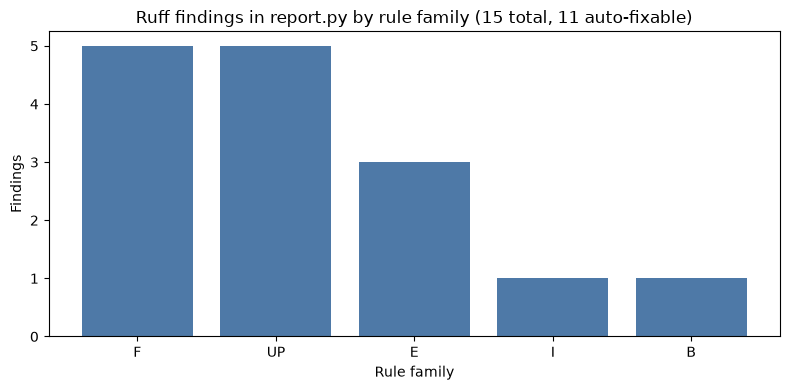

In [3]:
from collections import Counter

import matplotlib.pyplot as plt

findings = json.loads(subprocess.run([*ruff, "check", "--select", rules, "--output-format", "json", "--no-cache",
                                      str(messy)], capture_output=True, text=True).stdout)
by_family = Counter("".join(ch for ch in f["code"] if ch.isalpha()) for f in findings)
fixable = sum(1 for f in findings if f.get("fix"))

fig, ax = plt.subplots(figsize=(8, 4))
fams = sorted(by_family, key=by_family.get, reverse=True)
ax.bar(fams, [by_family[f] for f in fams], color="#4E79A7")
ax.set(title=f"Ruff findings in report.py by rule family ({len(findings)} total, {fixable} auto-fixable)",
       xlabel="Rule family", ylabel="Findings")
plt.tight_layout()
plt.show()

## 4. Fix and Format Automatically

`ruff check --fix` applies the **safe** fixes. `ruff format` then rewrites the layout (quotes, spaces, line breaks) in a style compatible with Black. The remaining findings need a human decision, for example the undefined name.

In [4]:
subprocess.run([*ruff, "check", "--select", rules, "--fix", "--unsafe-fixes", "--no-cache", str(messy)],
               capture_output=True, text=True)
subprocess.run([*ruff, "format", "--no-cache", str(messy)], capture_output=True, text=True)
print(messy.read_text())
remaining = subprocess.run([*ruff, "check", "--select", rules, "--output-format", "concise", "--no-cache", str(messy)],
                           capture_output=True, text=True).stdout
print("Remaining findings:\n" + remaining.replace(str(work) + "/", ""))

def build_report(rows: list[dict], tags=None):
    if tags is None:
        tags = []
    total = 0
    for i in range(len(rows)):
        row = rows[i]
        if row["amount"] is None:
            continue
        total = total + row["amount"]
    try:
        ratio = total / len(rows)
    except:
        ratio = 0
    tags.append("done")
    print(f"Total: {total}, ratio: {ratio}")
    return {"total": total, "ratio": ratio, "tags": tags, "unknown": undefined_name}

Remaining findings:
report.py:12:5: E722 Do not use bare `except`
report.py:16:70: F821 Undefined name `undefined_name`
Found 2 errors.



Ruff removed the unused imports, sorted the rest, replaced `List`/`Dict` with `list`/`dict`, rewrote `== None` as `is None`, and converted the `%` formatting to an f-string. It did **not** guess a value for `undefined_name`, and it reports the bare `except` and the mutable default: these need a decision from the developer.

## 5. Configure Ruff in `pyproject.toml`

```toml
[tool.ruff]
line-length = 120
target-version = "py312"
extend-include = ["*.ipynb"]          # lint notebooks too

[tool.ruff.lint]
select = ["F", "E", "W", "I", "B", "UP", "SIM"]
ignore = ["E501"]                     # line length is handled by the formatter

[tool.ruff.lint.per-file-ignores]
"tests/*" = ["S101"]                  # allow assert in tests
```

Run Ruff in three places: in the editor (the Ruff extension for VS Code), as a **pre-commit hook** (M03), and in **CI** so that no unformatted code reaches the main branch.

*Insight: Let tools decide style questions. A formatter ends discussions about spaces and quotes in code reviews, and a linter finds real bugs (undefined names, mutable defaults) before any test runs.*

## Real-World Use Case or Analogy

A linter is like the **spell checker and grammar checker** in a word processor: it underlines likely mistakes while you write. A formatter is like the **"apply style" button**: every heading and paragraph gets the same font and spacing, whoever wrote it.

Large open-source projects (FastAPI, pandas, Hugging Face Transformers, Apache Airflow) use Ruff in CI. A pull request with lint errors fails automatically, so reviewers can focus on the logic.